In [ ]:
import torch
import numpy as np
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cpu


In [ ]:
transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="data", train=True, download=True, transform=transform
)

test_data = datasets.FashionMNIST(
    root="data", train=False, download=True, transform=transform
)

print("Training images:", len(train_data))
print("Test images:", len(test_data))

Training images: 60000
Test images: 10000


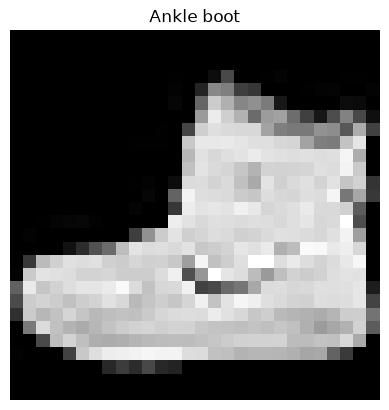

In [ ]:
import matplotlib.pyplot as plt

image, label = train_data[0]

plt.imshow(image.squeeze(0), cmap="gray")
plt.title(train_data.classes[label])
plt.axis("off")
plt.show()

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

In [ ]:
from torch import nn

model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
).to(device)

print(model)

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1568, out_features=64, bias=True)
  (8): ReLU()
  (9): Linear(in_features=64, out_features=10, bias=True)
)


In [ ]:
weights = torch.load("fashion_cnn.pth", map_location=device, weights_only=True)
model.load_state_dict(weights)
model.eval()

print("Shared model loaded.")

Shared model loaded.


In [ ]:
import torch.nn.functional as F

true_labels = []
predicted_labels = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        scores = model(images.to(device))
        probs = F.softmax(scores, dim=1)
        predictions = probs.argmax(dim=1)

        true_labels.extend(labels.tolist())
        predicted_labels.extend(predictions.cpu().tolist())
        all_probabilities.extend(probs.cpu().tolist())

all_probabilities = np.array(all_probabilities)
print("Predictions collected:", len(predicted_labels))
print("Probabilities shape:", all_probabilities.shape)

Predictions collected: 10000
Probabilities shape: (10000, 10)


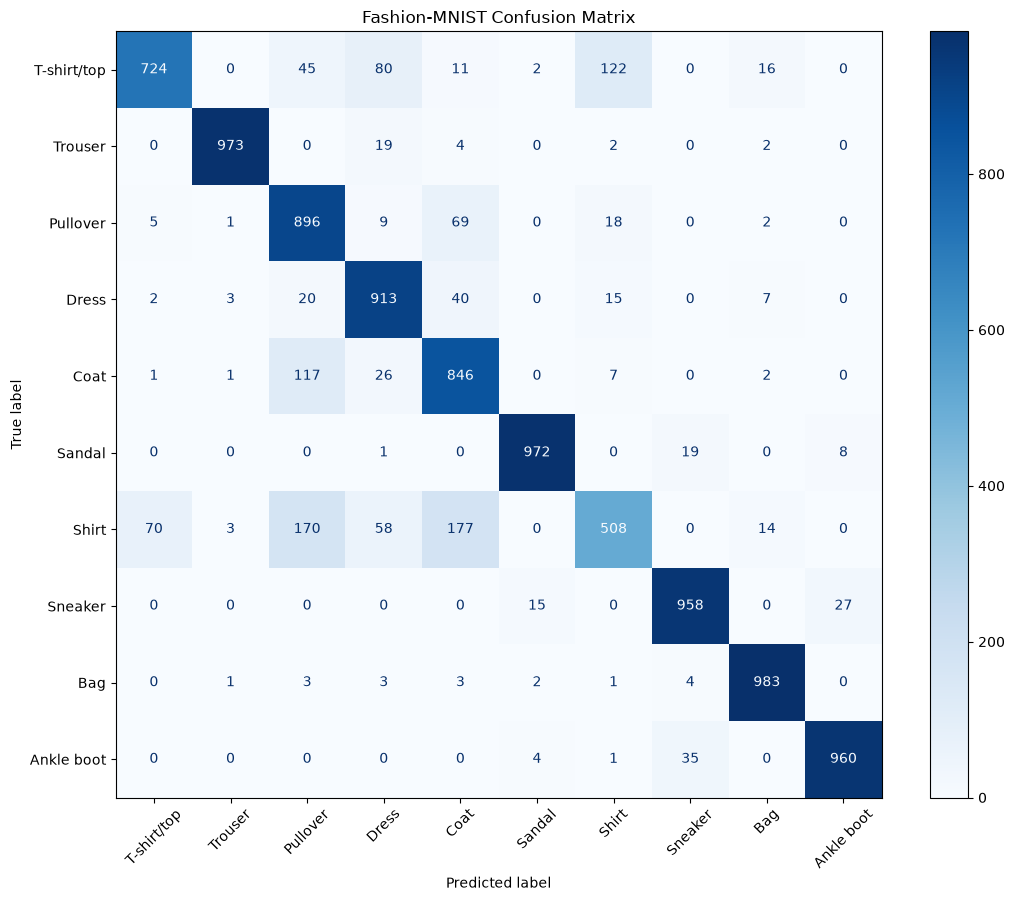

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = test_data.classes
matrix = confusion_matrix(
    true_labels, predicted_labels, labels=range(len(class_names))
)

fig, ax = plt.subplots(figsize=(11, 9))
display = ConfusionMatrixDisplay(matrix, display_labels=class_names)
display.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
ax.set_title("Fashion-MNIST Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

errors = matrix.copy()
np.fill_diagonal(errors, 0)  # Exclude correct predictions

row, col = np.unravel_index(errors.argmax(), errors.shape)
print(f"{class_names[row]} → {class_names[col]}: {errors[row, col]} images")

Shirt → Coat: 177 images


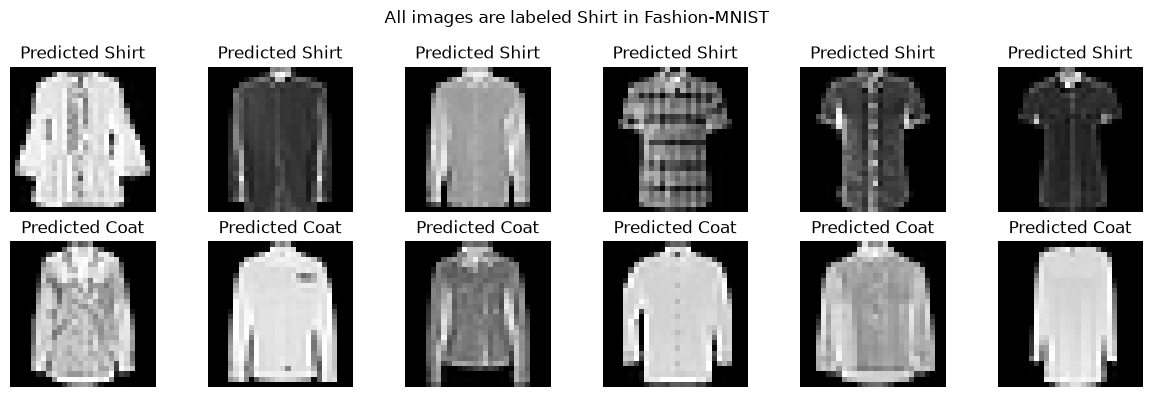

In [ ]:
actual = np.array(true_labels)
predicted = np.array(predicted_labels)

correct_shirts = np.flatnonzero((actual == row) & (predicted == row))
shirts_called_coats = np.flatnonzero((actual == row) & (predicted == col))

rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 6, figsize=(12, 4))

for plot_row, indices, title in [
    (0, correct_shirts, "Predicted Shirt"),
    (1, shirts_called_coats, "Predicted Coat"),
]:
    for ax, index in zip(axes[plot_row], rng.choice(indices, 6, replace=False)):
        image, _ = test_data[int(index)]
        ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")

fig.suptitle("All images are labeled Shirt in Fashion-MNIST")
plt.tight_layout()
plt.show()

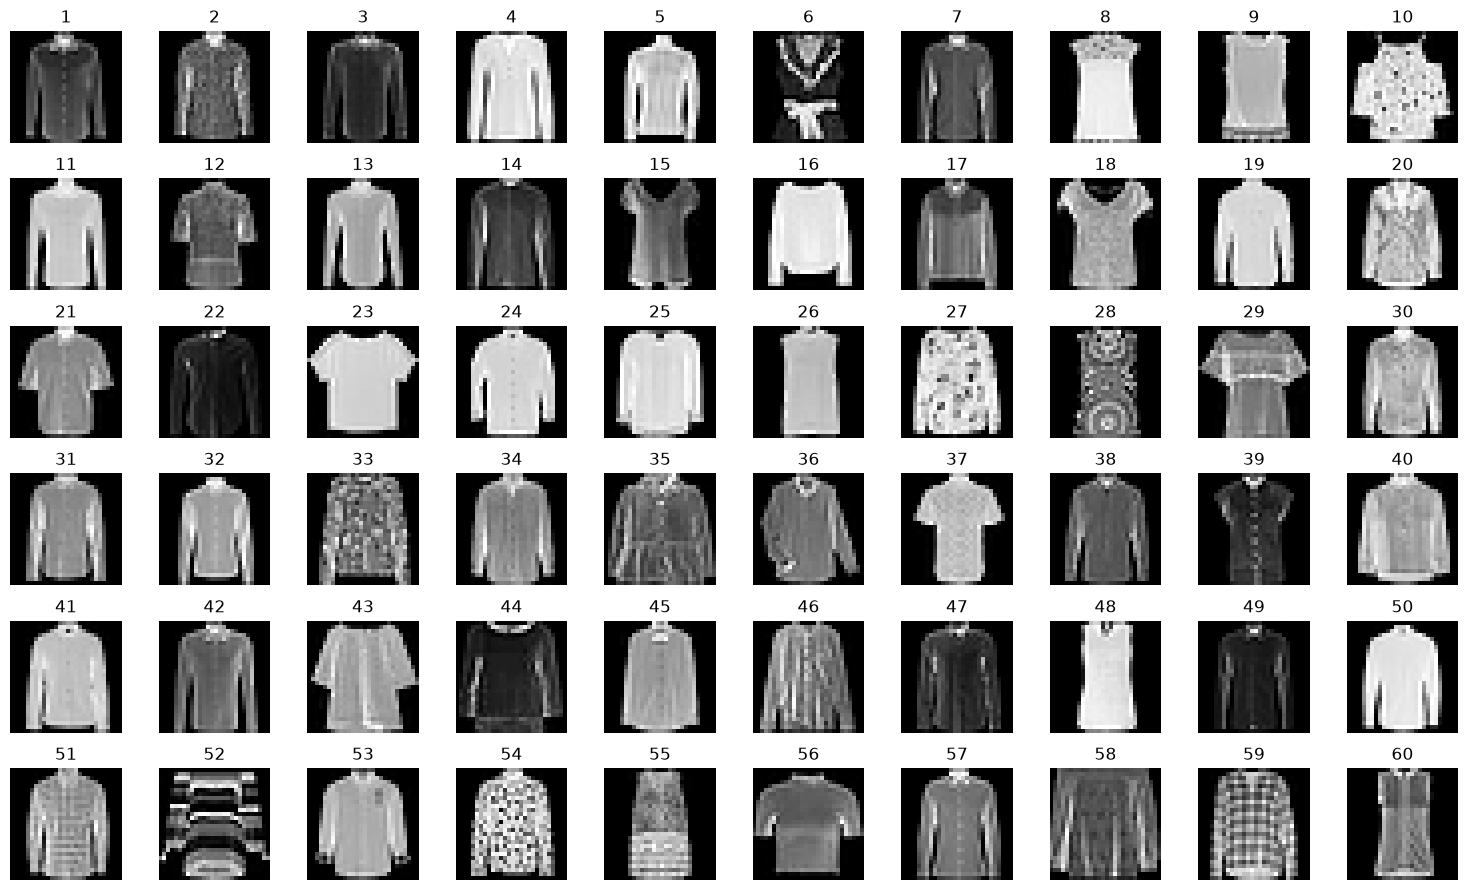

In [ ]:
shirt_indices = np.flatnonzero(actual == class_names.index("Shirt"))
sample_indices = np.random.default_rng(123).choice(
    shirt_indices, size=60, replace=False
)

fig, axes = plt.subplots(6, 10, figsize=(15, 9))
for number, (ax, index) in enumerate(zip(axes.flat, sample_indices), start=1):
    image, _ = test_data[int(index)]
    ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
    ax.set_title(str(number))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
shirt_indices = np.flatnonzero(actual == class_names.index("Shirt"))
coat_id = class_names.index("Coat")

coverage = []
for index in shirt_indices:
    image, _ = test_data[int(index)]
    pixels = image.squeeze(0).numpy()
    sides = np.concatenate([pixels[15:24, 2:8], pixels[15:24, 20:26]], axis=1)
    coverage.append((sides > 0.2).mean())

coverage = np.array(coverage)
higher_coverage = coverage > np.median(coverage)
called_coat = predicted[shirt_indices] == coat_id

for name, group in [
    ("Lower coverage", ~higher_coverage),
    ("Higher coverage", higher_coverage),
]:
    count = (called_coat & group).sum()
    total = group.sum()
    if total:
        print(f"{name}: {count}/{total} predicted Coat ({count / total:.1%})")

Lower coverage: 28/506 predicted Coat (5.5%)
Higher coverage: 149/494 predicted Coat (30.2%)


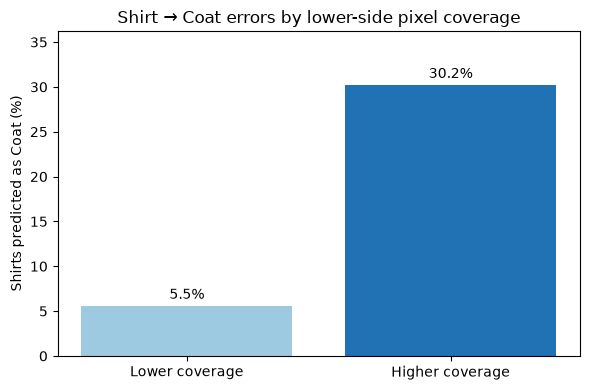

In [ ]:
groups = [~higher_coverage, higher_coverage]
rates = [100 * called_coat[group].mean() for group in groups]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Lower coverage", "Higher coverage"], rates,
              color=["#9ecae1", "#2171b5"])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, max(rates) * 1.2)
ax.set_ylabel("Shirts predicted as Coat (%)")
ax.set_title("Shirt → Coat errors by lower-side pixel coverage")
plt.tight_layout()
plt.show()

In [ ]:
shirt_id = class_names.index("Shirt")
called_shirt = predicted[shirt_indices] == shirt_id

for name, group in [
    ("Lower coverage", ~higher_coverage),
    ("Higher coverage", higher_coverage),
]:
    correct = (called_shirt & group).sum()
    total = group.sum()
    print(f"{name}: {correct}/{total} correctly predicted as Shirt ({correct / total:.1%})")

Lower coverage: 303/506 correctly predicted as Shirt (59.9%)
Higher coverage: 205/494 correctly predicted as Shirt (41.5%)


In the Fashion-MNIST test set, shirts with more bright pixels near the lower sides were correctly predicted as Shirt less often (41.5% vs. 59.9%) and were mistaken for Coat more often (30.2% vs. 5.5%). Sleeve length is one possible explanation, but we only measured pixel coverage.

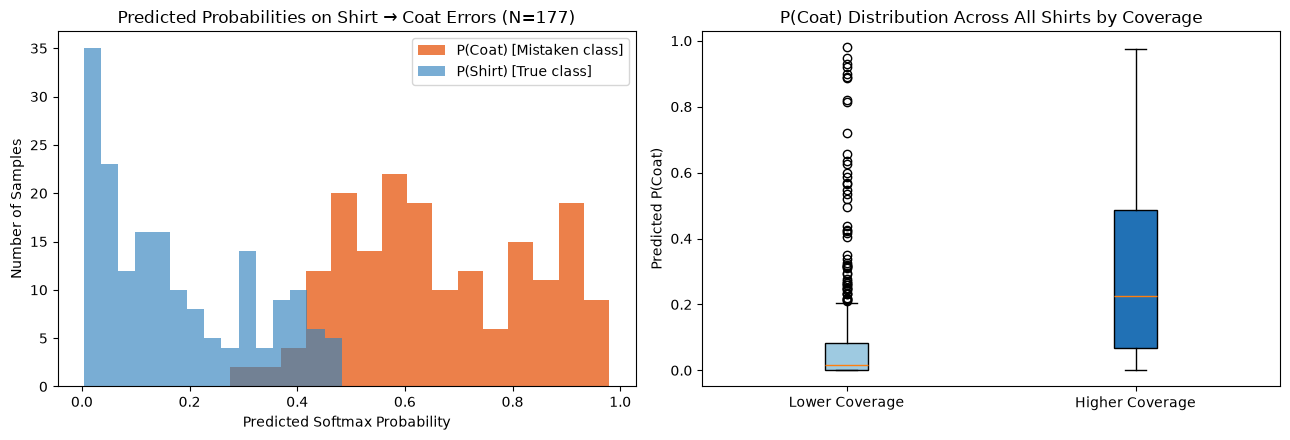

Errors (N=177):
  Mean P(Coat) assigned:  66.4%
  Mean P(Shirt) assigned: 17.4%

Across All Shirts:
  Mean P(Coat) in Lower Coverage:  8.0%
  Mean P(Coat) in Higher Coverage: 30.5%


In [ ]:
# 1. Map class IDs
shirt_id = class_names.index("Shirt")
coat_id = class_names.index("Coat")

# 2. Extract probabilities for the 177 Shirt -> Coat errors
shirt_to_coat_idx = np.flatnonzero((actual == shirt_id) & (predicted == coat_id))
p_coat_errors = all_probabilities[shirt_to_coat_idx, coat_id]
p_shirt_errors = all_probabilities[shirt_to_coat_idx, shirt_id]

# 3. Extract P(Coat) across ALL test shirts, grouped by lower-side pixel coverage
p_coat_all_shirts = all_probabilities[shirt_indices, coat_id]
p_coat_low_cov = p_coat_all_shirts[~higher_coverage]
p_coat_high_cov = p_coat_all_shirts[higher_coverage]

# 4. Plot probability visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Subplot 1: Prediction confidence on the 177 misclassifications
axes[0].hist(p_coat_errors, bins=15, color="#e6550d", alpha=0.75, label="P(Coat) [Mistaken class]")
axes[0].hist(p_shirt_errors, bins=15, color="#3182bd", alpha=0.65, label="P(Shirt) [True class]")
axes[0].set_xlabel("Predicted Softmax Probability")
axes[0].set_ylabel("Number of Samples")
axes[0].set_title("Predicted Probabilities on Shirt → Coat Errors (N=177)")
axes[0].legend()

# Subplot 2: Shift in P(Coat) by pixel coverage across all 1,000 shirts
bp = axes[1].boxplot([p_coat_low_cov, p_coat_high_cov],
                     tick_labels=["Lower Coverage", "Higher Coverage"],
                     patch_artist=True)
colors = ["#9ecae1", "#2171b5"]
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
axes[1].set_ylabel("Predicted P(Coat)")
axes[1].set_title("P(Coat) Distribution Across All Shirts by Coverage")

plt.tight_layout()
plt.show()

# 5. Numerical summary
print(f"Errors (N={len(shirt_to_coat_idx)}):")
print(f"  Mean P(Coat) assigned:  {p_coat_errors.mean():.1%}")
print(f"  Mean P(Shirt) assigned: {p_shirt_errors.mean():.1%}")
print("\nAcross All Shirts:")
print(f"  Mean P(Coat) in Lower Coverage:  {p_coat_low_cov.mean():.1%}")
print(f"  Mean P(Coat) in Higher Coverage: {p_coat_high_cov.mean():.1%}")

In [ ]:
brightness = np.array([
    test_data[int(index)][0].mean().item()
    for index in shirt_indices
])

boundaries = np.quantile(brightness, [0.25, 0.50, 0.75])
brightness_groups = np.digitize(brightness, boundaries)

for level in range(4):
    print(f"\nBrightness range {level + 1} (darkest to brightest)")

    for name, coverage_group in [
        ("Lower coverage", ~higher_coverage),
        ("Higher coverage", higher_coverage),
    ]:
        group = (brightness_groups == level) & coverage_group

        if group.any():
            average = p_coat_all_shirts[group].mean()
            print(
                f"{name}: {group.sum()} shirts, "
                f"average Coat score = {average:.1%}"
            )


Brightness range 1 (darkest to brightest)
Lower coverage: 198 shirts, average Coat score = 10.1%
Higher coverage: 52 shirts, average Coat score = 21.1%

Brightness range 2 (darkest to brightest)
Lower coverage: 135 shirts, average Coat score = 6.8%
Higher coverage: 115 shirts, average Coat score = 31.0%

Brightness range 3 (darkest to brightest)
Lower coverage: 122 shirts, average Coat score = 7.1%
Higher coverage: 128 shirts, average Coat score = 33.3%

Brightness range 4 (darkest to brightest)
Lower coverage: 51 shirts, average Coat score = 4.8%
Higher coverage: 199 shirts, average Coat score = 30.9%


For the 177 shirts mistaken for coats, the model gave Coat an average score of 66.4% and Shirt 17.4%. Across all 1,000 shirts, the average Coat score was 8.0% for lower coverage and 30.5% for higher coverage. Shirts with higher coverage tended to receive higher Coat scores. Long sleeves could help explain this pattern.

We also compared shirts within four ranges of overall brightness. Higher-coverage shirts had higher average Coat scores in every range, from 21.1–33.3%, compared with 4.8–10.1% for lower coverage. This suggests overall brightness alone may not explain the difference. Sleeve length and clothing width remain possible explanations.